# ¿Mismo título, mismo ingreso?
## Ingresos laborales de mujeres y hombres con educación superior en Colombia (GEIH, enero–julio 2026)

**Visualización I · Proyecto 3 · Componente Python (Seaborn y Plotly)**
Equipo 3: Alejandro Pardo Costo y Juan Tomás Rincón Pinzón

### Instalación de dependencias

**¿Hay que correrla?**
- **En VS Code o Jupyter local:** sí, la primera vez, si el entorno no tiene estas librerías. Si ya están instaladas, la celda solo confirma que existen y sigue. `nbformat` hace falta para que los gráficos de Plotly (`fig.show()`) se vean dentro de VS Code.
- **En Google Colab:** no es obligatoria, porque Colab ya trae pandas, numpy, matplotlib, seaborn y plotly. Correrla no hace daño: tarda unos segundos y no cambia nada. La dejamos para que "Ejecutar todas" funcione igual en los dos entornos.

Si aparece el mensaje "you may need to restart the kernel", no hace falta reiniciar cuando las librerías ya estaban instaladas.

In [1]:
%pip install -q pandas numpy matplotlib seaborn plotly nbformat

Note: you may need to restart the kernel to use updated packages.


## 1. Para quién es este análisis

| | |
|---|---|
| **Audiencia** | Mujeres de 18 a 28 años que están terminando o acaban de terminar un programa técnico, tecnológico o universitario y van a buscar su primer empleo. |
| **Qué necesitan entender** | Si con el mismo nivel educativo las mujeres reciben lo mismo que los hombres, y si esa diferencia cambia con la edad, el sector donde se trabaja y el departamento. Con eso pueden llegar mejor informadas a una entrevista o a una negociación salarial. |
| **Pregunta analítica** | ¿Qué diferencias de ingreso laboral se observan entre mujeres y hombres con educación superior en Colombia (enero–julio 2026) y cómo varían según la edad y el departamento? |

Este notebook es una de las tres piezas del proyecto. Cada herramienta responde una parte distinta de la pregunta para no repetir gráficos:

| Herramienta | Qué aporta a la historia |
|---|---|
| Power BI | Panorama general: ingreso promedio por nivel educativo y sexo, evolución mensual, cotización a pensión y detalle por ciudad. |
| **Python, Seaborn (este notebook)** | (1) Cómo se reparten los ingresos por hora, no solo el promedio. (2) Cómo cambia la brecha según la edad. |
| **Python, Plotly (este notebook)** | Exploración por sector económico y grupo de edad. |
| R | Mapa de la brecha por departamento. Este notebook prepara la tabla que usa el mapa. |

Las definiciones están en `docs/Definiciones_compartidas.md` y son las mismas en las tres herramientas.

## 2. Datos y preparación

**Fuente.** Gran Encuesta Integrada de Hogares (GEIH) 2026 del DANE, marco 2018, meses de enero a julio. Usamos las mismas tablas del Proyecto 1:

- *Características generales, seguridad social en salud y educación*: sexo, edad, nivel educativo y departamento de cada persona.
- *Ocupados*: ingreso laboral, horas trabajadas, rama de actividad y factor de expansión.

Los 14 archivos CSV (2 tablas × 7 meses) vienen dentro de `datos/originales/geih_2026/Tablas_Seleccionadas_GEIH_2026.zip`. El zip no se modifica: el notebook lo lee directamente y toda la preparación ocurre en memoria.

In [2]:
from pathlib import Path
import io
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import plotly.graph_objects as go

# El notebook vive en python/, pero también se puede abrir desde la raíz del repo o desde Colab.
ZIP_RELATIVO = Path("datos/originales/geih_2026/Tablas_Seleccionadas_GEIH_2026.zip")
URL_ZIP = ("https://github.com/AlejandroP212/proyecto3-narrativa-visual/raw/main/"
           "datos/originales/geih_2026/Tablas_Seleccionadas_GEIH_2026.zip")

BASE = next((c for c in [Path("."), Path("..")] if (c / ZIP_RELATIVO).exists()), None)
if BASE is None:
    # En Colab no está el repo clonado: descargamos el mismo zip desde GitHub
    BASE = Path(".")
    (BASE / ZIP_RELATIVO).parent.mkdir(parents=True, exist_ok=True)
    try:
        urllib.request.urlretrieve(URL_ZIP, BASE / ZIP_RELATIVO)
    except Exception as error:
        raise FileNotFoundError(
            "No se encontró el zip de la GEIH ni se pudo descargar. "
            "Abre el notebook desde la carpeta python/ del repositorio."
        ) from error

RUTA_ZIP = BASE / ZIP_RELATIVO
CARPETA_PROCESADOS = BASE / "datos" / "procesados"
CARPETA_HTML = BASE / "python" / "html"
CARPETA_IMG = BASE / "presentacion" / "img"
for carpeta in (CARPETA_PROCESADOS, CARPETA_HTML, CARPETA_IMG):
    carpeta.mkdir(parents=True, exist_ok=True)

print("Datos:", RUTA_ZIP.resolve())

Datos: /home/ana/code/Semestre_5/Visualizacion_1/Proyecto_3/datos/originales/geih_2026/Tablas_Seleccionadas_GEIH_2026.zip


### Configuración general: colores, categorías y formatos

En esta celda dejamos fijos los colores, las categorías y los formatos que se usan en todos los gráficos. Los colores son los mismos del Power BI y del mapa en R: azul para hombres y ocre para mujeres. La pareja azul/morado del Proyecto 1 no se distinguía bien con daltonismo, por eso la cambiamos.

In [3]:
COLORES = {"Hombre": "#1F4E79", "Mujer": "#B8862B"}
ACENTO = "#AD4A3C"      # se usa para resaltar la brecha
NEUTRO = "#6B7280"      # textos secundarios y barras sin resaltar
GRIS_CLARO = "#D1D5DB"
ORDEN_SEXO = ["Hombre", "Mujer"]

# P3042 = nivel educativo más alto alcanzado. Educación superior = códigos 8 a 13.
NIVEL_SUPERIOR = {
    8: "Técnica o tecnológica", 9: "Técnica o tecnológica",
    10: "Universitaria",
    11: "Posgrado", 12: "Posgrado", 13: "Posgrado",
}
ORDEN_NIVEL = ["Técnica o tecnológica", "Universitaria", "Posgrado"]

# Grupos de edad (P6040). 18–28 es el rango de juventud de la Ley 1622 de 2013.
CORTES_EDAD = [17, 28, 40, 59, 120]
ORDEN_EDAD = ["18–28", "29–40", "41–59", "60 y más"]

# Secciones de la CIIU Rev. 4 A.C. a partir de la división de dos dígitos (RAMA2D_R4)
SECCIONES_CIIU = [
    (1, 3, "Agro y pesca"), (5, 9, "Minería"), (10, 33, "Industria manufacturera"),
    (35, 39, "Electricidad, gas y agua"), (41, 43, "Construcción"),
    (45, 47, "Comercio y reparación de vehículos"), (49, 53, "Transporte y almacenamiento"),
    (55, 56, "Alojamiento y servicios de comida"), (58, 63, "Información y comunicaciones"),
    (64, 66, "Finanzas y seguros"), (68, 68, "Actividades inmobiliarias"),
    (69, 75, "Actividades profesionales y científicas"),
    (77, 82, "Servicios administrativos y de apoyo"),
    (84, 84, "Administración pública y defensa"), (85, 85, "Educación"),
    (86, 88, "Salud y asistencia social"), (90, 93, "Arte y entretenimiento"),
    (94, 96, "Otros servicios"), (97, 98, "Hogares como empleadores"),
    (99, 99, "Organizaciones extraterritoriales"),
]

FUENTE = "Fuente: DANE, GEIH enero–julio 2026. Cálculos del Equipo 3."
SEMANAS_POR_MES = 4.3333   # el mismo factor que usa Power BI


def miles(valor):
    # 1234567 -> '1.234.567'
    return f"{valor:,.0f}".replace(",", ".")


def pct(valor, decimales=1):
    # 13.67 -> '13,7 %'
    return f"{valor:.{decimales}f}".replace(".", ",") + " %"


sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
})

### Carga

Los CSV del DANE vienen separados por `;` y con codificación latin-1. Solo leemos las columnas que usa el análisis:

| Tabla | Columnas | Para qué |
|---|---|---|
| Ambas | `DIRECTORIO`, `SECUENCIA_P`, `HOGAR`, `ORDEN`, `PERIODO` | Llave para unir las dos tablas |
| Características | `P3271` sexo, `P6040` edad, `P3042` nivel educativo, `DPTO` departamento, `MES` | Variables de comparación |
| Ocupados | `INGLABO` ingreso laboral mensual, `P6800` horas por semana, `RAMA2D_R4` rama, `P6430` posición ocupacional, `FEX_C18` factor de expansión | Ingresos, ponderación y revisión de excluidos |

El archivo de abril se llama distinto ("Capítulos de características…"), así que buscamos las tablas por una parte del nombre y no por el nombre exacto.

In [4]:
LLAVE = ["DIRECTORIO", "SECUENCIA_P", "HOGAR", "ORDEN", "PERIODO"]
COLS_PERSONAS = LLAVE + ["MES", "DPTO", "P3271", "P6040", "P3042"]
COLS_OCUPADOS = LLAVE + ["INGLABO", "P6800", "RAMA2D_R4", "P6430", "FEX_C18"]

personas, ocupados = [], []
with zipfile.ZipFile(RUTA_ZIP) as z:
    for nombre in sorted(z.namelist()):
        if not nombre.upper().endswith(".CSV"):
            continue
        opciones = dict(sep=";", dtype=str, encoding="latin-1")
        if "generales" in nombre:
            personas.append(pd.read_csv(z.open(nombre), usecols=COLS_PERSONAS, **opciones))
        elif "Ocupados" in nombre:
            ocupados.append(pd.read_csv(z.open(nombre), usecols=COLS_OCUPADOS, **opciones))

personas = pd.concat(personas, ignore_index=True)
ocupados = pd.concat(ocupados, ignore_index=True)

print(f"Personas encuestadas: {miles(len(personas))}  |  Ocupados: {miles(len(ocupados))}")
personas.groupby("MES").size().rename("personas").to_frame().join(
    ocupados.assign(MES=ocupados["PERIODO"].str[4:6]).groupby("MES").size().rename("ocupados")
)

Personas encuestadas: 468.434  |  Ocupados: 206.712


,personas,ocupados
MES,,
01,66606,28359
02,67736,29892
03,66909,29691
04,67349,29874
05,67065,29920
06,66285,29459
07,66484,29517


### Unión de las tablas

Cada ocupado debe tener exactamente una fila en la tabla de características. Por eso se une con la llave completa e incluye `HOGAR`: sin ella se duplican personas que comparten vivienda, un error que ya habíamos encontrado en el Proyecto 1. Con `validate="1:1"`, pandas detiene la ejecución si aparece algún duplicado.

In [5]:
base = ocupados.merge(personas, on=LLAVE, how="left", validate="1:1", indicator=True)
sin_pareja = (base["_merge"] != "both").sum()
print(f"Ocupados sin pareja en características: {sin_pareja}")
base = base.drop(columns="_merge")

Ocupados sin pareja en características: 0


### Variables y filtros

Pasos de la preparación:

1. Las columnas numéricas llegan como texto y se convierten. `FEX_C18` usa punto decimal, así que se lee sin ajustes. En Power Query fue necesario cambiar la configuración regional.
2. **Ingreso por hora** = ingreso mensual ÷ (horas por semana × 4,3333).
3. Se conservan solo los ocupados con ingreso laboral mayor que 0, horas mayores que 0 y educación superior (P3042 entre 8 y 13).

La tabla de abajo muestra cuántos registros sale en cada filtro, para que quede claro qué se excluye.

In [6]:
for col in ["INGLABO", "P6800", "P6040", "P3042", "RAMA2D_R4"]:
    base[col] = pd.to_numeric(base[col], errors="coerce")
base["FEX"] = pd.to_numeric(base["FEX_C18"])
base["sexo"] = base["P3271"].map({"1": "Hombre", "2": "Mujer"})
base["HORAS_MES"] = base["P6800"] * SEMANAS_POR_MES

pasos = [("Ocupados enero–julio", len(base))]
datos = base[base["INGLABO"] > 0]
pasos.append(("Con ingreso laboral mayor que 0", len(datos)))
datos = datos[datos["P6800"] > 0]
pasos.append(("Con horas trabajadas mayores que 0", len(datos)))
datos = datos[datos["P3042"].between(8, 13)].copy()
pasos.append(("Con educación superior (P3042 = 8 a 13)", len(datos)))

datos["nivel"] = pd.Categorical(datos["P3042"].map(NIVEL_SUPERIOR), ORDEN_NIVEL, ordered=True)
datos["grupo_edad"] = pd.cut(datos["P6040"], CORTES_EDAD, labels=ORDEN_EDAD)
datos["ingreso_hora"] = datos["INGLABO"] / datos["HORAS_MES"]


def seccion_ciiu(division):
    for desde, hasta, nombre in SECCIONES_CIIU:
        if desde <= division <= hasta:
            return nombre
    return None


datos["sector"] = datos["RAMA2D_R4"].map(seccion_ciiu)

pd.DataFrame(pasos, columns=["Paso", "Registros"]).assign(
    Registros=lambda t: t["Registros"].map(miles))

,Paso,Registros
0,Ocupados enero–julio,206.712
1,Con ingreso laboral mayor que 0,201.277
2,Con horas trabajadas mayores que 0,201.277
3,Con educación superior (P3042 = 8 a 13),76.488


In [7]:
# Revisión rápida de faltantes y rangos en la tabla final
print("Faltantes por columna:")
print(datos[["sexo", "P6040", "grupo_edad", "nivel", "sector", "DPTO", "FEX"]].isna().sum().to_string())
print(f"\nMenores de 18 con educación superior (quedan fuera de los grupos de edad): "
      f"{datos['grupo_edad'].isna().sum()}")
print(f"Viviendas distintas: {miles(datos['DIRECTORIO'].nunique())}")
print(f"Departamentos: {datos['DPTO'].nunique()}")

Faltantes por columna:
sexo           0
P6040          0
grupo_edad    86
nivel          0
sector         0
DPTO           0
FEX            0

Menores de 18 con educación superior (quedan fuera de los grupos de edad): 86
Viviendas distintas: 58.995
Departamentos: 33


**Lectura.** De 206.712 ocupados quedan 76.488 personas con educación superior, ingreso y horas reportadas. Ninguna columna clave tiene faltantes. Las 86 personas menores de 18 años con educación superior entran en las cifras generales, pero no en los grupos de edad.

**¿Quién queda fuera del análisis y por qué importa?** La celda siguiente lo muestra. Hay dos tipos de exclusiones:

1. **Personas que trabajan pero no reportan un ingreso mayor que 0** (5.435 ocupados; 1.535 de ellos con educación superior). La mayoría son *trabajadores familiares sin remuneración*: por ejemplo, una contadora graduada que ayuda en el negocio de su familia sin recibir sueldo. Se excluyen porque sin ingreso no se puede calcular cuánto gana por hora.
2. **Personas que no trabajan.** La tabla *Ocupados* solo incluye a quienes trabajaron en la semana de la encuesta. Por ejemplo, una tecnóloga recién graduada que está buscando su primer empleo, o una profesional que se dedica al cuidado de su hogar, **no aparecen** en el cálculo.

Esto significa que la brecha compara a mujeres y hombres **que ya tienen un trabajo remunerado**. No mide si a las mujeres les cuesta más conseguir empleo. Esa sería otra brecha, y estos datos no la incluyen.

In [8]:
# ¿Quiénes salen con el filtro de ingreso? Posición ocupacional (P6430) de los excluidos
POSICION = {
    1: "Empleado de empresa particular", 2: "Empleado del gobierno", 3: "Empleado doméstico",
    4: "Trabajador por cuenta propia", 5: "Patrón o empleador",
    6: "Trabajador familiar sin remuneración", 7: "Trabajador sin remuneración en otros hogares",
    8: "Jornalero o peón", 9: "Otro",
}
sin_ingreso = base[~(base["INGLABO"] > 0)]
print(f"Ocupados sin ingreso mayor que 0: {miles(len(sin_ingreso))} "
      f"({miles(sin_ingreso['INGLABO'].isna().sum())} no lo informaron y "
      f"{miles((sin_ingreso['INGLABO'] == 0).sum())} reportaron 0)")
print(f"De ellos, con educación superior: {miles(sin_ingreso['P3042'].between(8, 13).sum())}")
(pd.to_numeric(sin_ingreso["P6430"], errors="coerce").map(POSICION)
   .value_counts().rename("personas").to_frame())

Ocupados sin ingreso mayor que 0: 5.435 (3.983 no lo informaron y 1.452 reportaron 0)
De ellos, con educación superior: 1.535


,personas
P6430,
Trabajador familiar sin remuneración,3250
Trabajador por cuenta propia,1596
Patrón o empleador,297
Empleado de empresa particular,207
Empleado del gobierno,78
Trabajador sin remuneración en otros hogares,3
Empleado doméstico,2
Jornalero o peón,2


### Cómo se calculan las cifras

Todas las cifras están **ponderadas por el factor de expansión** (`FEX_C18`). La GEIH no entrevista a todo el país: entrevista a una muestra, y a cada persona le asigna un peso que dice a cuántas personas representa. Si alguien tiene FEX = 200, "cuenta" por 200 personas parecidas a ella. Sin ponderar, los grupos que la encuesta entrevistó de más pesarían de más.

| Cifra | Qué mide | Cómo se calcula | Cómo se lee |
|---|---|---|---|
| **Ingreso mensual promedio** | Lo que una persona recibe en un mes por su trabajo (salario, honorarios o ganancia del negocio) | Σ(ingreso × FEX) / Σ(FEX) | "En promedio, una mujer con educación superior recibe $ X al mes." |
| **Ingreso por hora** | Cuánto se paga, en promedio, por cada hora trabajada | Σ(ingreso × FEX) / Σ(horas del mes × FEX). Es el total de ingresos del grupo dividido por el total de horas del grupo, igual que la medida `Ingreso_Hora_Promedio` de Power BI | "Por cada hora trabajada, el grupo recibe $ X." |
| **Brecha (%)** | Qué tanto menos reciben las mujeres que los hombres, en proporción a lo que reciben los hombres | (hombres − mujeres) / hombres × 100 | "Una brecha de 13,7 % significa que **por cada $ 100 que recibe un hombre, una mujer recibe $ 86,30**." Si es negativa, las mujeres reciben más. |
| **Diferencia entre dos brechas** | Cuánto cambia la brecha de un grupo a otro | Resta simple, en **puntos porcentuales** | Pasar de 7,4 % a 14,1 % es una diferencia de 6,7 *puntos*, no de 6,7 %. |

### Margen de error: ¿qué tan confiable es cada cifra?

**El problema.** La GEIH es una muestra. Si el DANE hubiera visitado otras viviendas, la brecha habría salido un poco distinta: 13,5 %, 14,1 %, 12,9 %… Una cifra sola no dice cuánto puede moverse. Para saberlo calculamos un **intervalo de confianza del 95 %**: el rango dentro del cual esperamos que esté el valor real.

**Cómo lo calculamos (bootstrap).** No podemos repetir la encuesta, así que simulamos repetirla con los mismos datos:

1. Tomamos las 58.995 viviendas de la muestra.
2. Armamos una "muestra nueva" en la que algunas viviendas salen dos o tres veces y otras no salen. Técnicamente, cada vivienda recibe un peso aleatorio de 0, 1, 2… (distribución de Poisson con promedio 1).
3. Con esa muestra nueva recalculamos la brecha.
4. Repetimos los pasos 2 y 3 **500 veces**. Obtenemos 500 brechas un poco distintas.
5. Ordenamos las 500 y descartamos el 2,5 % más bajo y el 2,5 % más alto. Lo que queda es el intervalo del 95 %.

**Por qué por vivienda y no por persona.** Las personas que viven juntas se parecen (mismo barrio, mismo estrato). Si se remuestrearan personas sueltas, el método creería que tiene más información independiente de la que realmente tiene, y el intervalo saldría demasiado estrecho.

**Cómo se lee un intervalo.**
- *Intervalo estrecho* (por ejemplo, de 11,2 % a 16,3 %): la cifra es confiable.
- *Intervalo ancho* (por ejemplo, de 8,9 % a 27,0 % en los mayores de 60): hay pocas personas en la muestra y la cifra es poco precisa.
- *Intervalo que incluye el 0* (por ejemplo, de −5 % a 10 %): con estos datos **no se puede afirmar que haya brecha**. Puede haberla o no.

**Limitación.** El DANE calcula sus márgenes de error con el diseño completo de la encuesta (estratos y conglomerados), que no viene en las tablas públicas. Nuestro bootstrap es una aproximación y los intervalos reales pueden ser algo más amplios.

La figura que aparece después de las cifras de control muestra las 500 repeticiones.

In [9]:
def ingreso_mensual(tabla):
    return np.average(tabla["INGLABO"], weights=tabla["FEX"])


def ingreso_por_hora(tabla):
    return (tabla["INGLABO"] * tabla["FEX"]).sum() / (tabla["HORAS_MES"] * tabla["FEX"]).sum()


def brecha(tabla, medida=ingreso_por_hora):
    hombres = medida(tabla[tabla["sexo"] == "Hombre"])
    mujeres = medida(tabla[tabla["sexo"] == "Mujer"])
    return (hombres - mujeres) / hombres * 100


def brecha_con_intervalo(tabla, repeticiones=500, semilla=2026, devolver_repeticiones=False):
    # Totales por vivienda y sexo: así cada repetición es una multiplicación de matrices
    sumas = (tabla.assign(I=tabla["INGLABO"] * tabla["FEX"], H=tabla["HORAS_MES"] * tabla["FEX"])
                  .groupby(["DIRECTORIO", "sexo"])[["I", "H"]].sum()
                  .unstack(fill_value=0))
    ingreso = sumas["I"][ORDEN_SEXO].to_numpy()   # columnas: Hombre, Mujer
    horas = sumas["H"][ORDEN_SEXO].to_numpy()

    pesos = np.random.default_rng(semilla).poisson(1, size=(repeticiones, len(sumas)))
    por_hora = (pesos @ ingreso) / (pesos @ horas)  # ingreso por hora en cada repetición
    brechas = (1 - por_hora[:, 1] / por_hora[:, 0]) * 100

    puntual = brecha(tabla)
    if devolver_repeticiones:
        return puntual, brechas
    return {
        "brecha": puntual,
        "ic_inf": np.percentile(brechas, 2.5),
        "ic_sup": np.percentile(brechas, 97.5),
        "cv_hombres": por_hora[:, 0].std() / por_hora[:, 0].mean() * 100,
        "cv_mujeres": por_hora[:, 1].std() / por_hora[:, 1].mean() * 100,
    }


def mediana_ponderada(valores, pesos):
    orden = np.argsort(valores.to_numpy())
    v, w = valores.to_numpy()[orden], pesos.to_numpy()[orden]
    acumulado = np.cumsum(w)
    return v[np.searchsorted(acumulado, acumulado[-1] / 2)]

### Cifras de control

Estas son las cifras centrales del proyecto. Deben dar igual en Power BI (consulta DAX de `LEEME_TOMAS.md`) y en este notebook. Debajo de la tabla, la celda traduce cada brecha a "pesos por cada $ 100" y compara las horas trabajadas.

In [10]:
total_sup = brecha_con_intervalo(datos)
brecha_mes = brecha(datos, ingreso_mensual)
horas_semana = {s: np.average(datos.loc[datos.sexo == s, "P6800"], weights=datos.loc[datos.sexo == s, "FEX"])
                for s in ORDEN_SEXO}

control = pd.DataFrame({
    "Indicador": [
        "Ingreso mensual promedio, hombres", "Ingreso mensual promedio, mujeres",
        "Brecha de ingreso mensual", "Horas trabajadas por semana, hombres",
        "Horas trabajadas por semana, mujeres", "Ingreso por hora, hombres",
        "Ingreso por hora, mujeres", "Brecha de ingreso por hora", "IC 95 % de la brecha por hora",
    ],
    "Valor": [
        "$ " + miles(ingreso_mensual(datos[datos.sexo == "Hombre"])),
        "$ " + miles(ingreso_mensual(datos[datos.sexo == "Mujer"])),
        pct(brecha_mes),
        f"{horas_semana['Hombre']:.1f}".replace(".", ","),
        f"{horas_semana['Mujer']:.1f}".replace(".", ","),
        "$ " + miles(ingreso_por_hora(datos[datos.sexo == "Hombre"])),
        "$ " + miles(ingreso_por_hora(datos[datos.sexo == "Mujer"])),
        pct(total_sup["brecha"]),
        f"{pct(total_sup['ic_inf'])} a {pct(total_sup['ic_sup'])}",
    ],
})
print(f"Al mes:   por cada $ 100 que recibe un hombre, una mujer recibe $ {100 - round(brecha_mes, 1):.2f}".replace(".", ","))
print(f"Por hora: por cada $ 100 que recibe un hombre, una mujer recibe $ {100 - round(total_sup['brecha'], 1):.2f}".replace(".", ","))
print(f"Diferencia entre la brecha mensual y la por hora: {brecha_mes - total_sup['brecha']:.1f} puntos porcentuales".replace(".", ","))
control

Al mes:   por cada $ 100 que recibe un hombre, una mujer recibe $ 81,50
Por hora: por cada $ 100 que recibe un hombre, una mujer recibe $ 86,30
Diferencia entre la brecha mensual y la por hora: 4,8 puntos porcentuales


,Indicador,Valor
0,"Ingreso mensual promedio, hombres",$ 4.068.584
1,"Ingreso mensual promedio, mujeres",$ 3.317.843
2,Brecha de ingreso mensual,"18,5 %"
3,"Horas trabajadas por semana, hombres","43,7"
4,"Horas trabajadas por semana, mujeres","41,3"
5,"Ingreso por hora, hombres",$ 21.491
6,"Ingreso por hora, mujeres",$ 18.553
7,Brecha de ingreso por hora,"13,7 %"
8,IC 95 % de la brecha por hora,"11,2 % a 16,3 %"


**Lectura, cifra por cifra.**

- **Brecha mensual: 18,5 %.**
  - *Qué mide:* la diferencia en lo que reciben al mes, en promedio, mujeres y hombres ocupados con educación superior.
  - *Cómo se mide:* ingreso mensual promedio de los hombres ($ 4.068.584) frente al de las mujeres ($ 3.317.843).
  - *Qué transmite:* **por cada $ 100 que recibe al mes un hombre con educación superior, una mujer con educación superior recibe $ 81,50.**
- **Horas:** los hombres trabajan en promedio 43,7 horas a la semana y las mujeres 41,3. Una parte de la diferencia mensual coincide con que ellas tienen menos horas remuneradas.
- **Brecha por hora: 13,7 %.**
  - *Qué mide:* la diferencia en lo que se paga por cada hora trabajada. Al dividir por las horas, se deja de lado que unos trabajen más que otros.
  - *Cómo se mide:* $ 21.491 por hora para los hombres frente a $ 18.553 para las mujeres.
  - *Qué transmite:* **aun trabajando la misma cantidad de horas, por cada $ 100 que recibe un hombre, una mujer recibe $ 86,30.**
- **De 18,5 % a 13,7 %:** al pasar a la medida por hora la brecha baja 4,8 puntos porcentuales, pero no desaparece. La diferencia en horas explica solo una parte.
- **Intervalo de 11,2 % a 16,3 %:** aunque la muestra fuera otra, la brecha por hora seguiría claramente por encima de 0. No es un resultado del azar.

Desde aquí usamos la brecha **por hora** como medida principal, porque compara a personas con jornadas distintas en igualdad de condiciones.

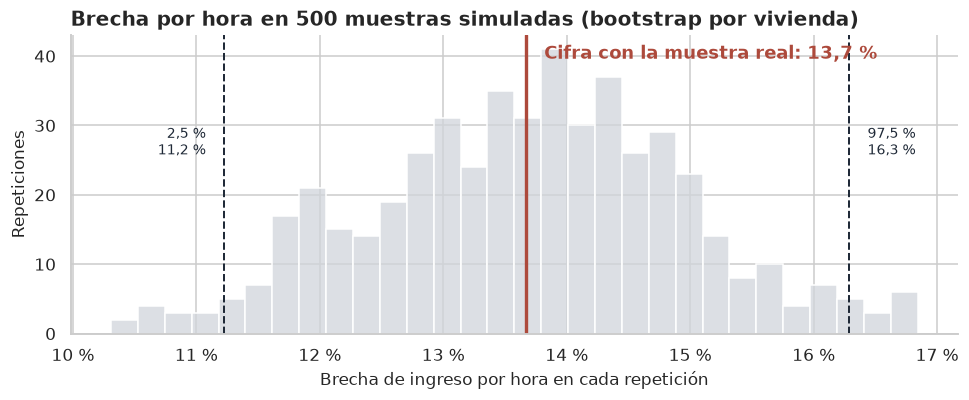

In [11]:
# Figura de apoyo: las 500 repeticiones del bootstrap para la brecha por hora (educación superior)
puntual, repeticiones = brecha_con_intervalo(datos, devolver_repeticiones=True)

fig, ax = plt.subplots(figsize=(9, 3.8))
sns.histplot(repeticiones, bins=30, color=GRIS_CLARO, edgecolor="white", ax=ax)
for limite_ic in (total_sup["ic_inf"], total_sup["ic_sup"]):
    ax.axvline(limite_ic, color="#1F2937", linestyle="--", linewidth=1.3)
ax.axvline(puntual, color=ACENTO, linewidth=2.2)
ax.text(puntual + 0.15, ax.get_ylim()[1] * 0.92, f"Cifra con la muestra real: {pct(puntual)}",
        color=ACENTO, fontweight="bold")
ax.text(total_sup["ic_inf"] - 0.15, ax.get_ylim()[1] * 0.6, f"2,5 %\n{pct(total_sup['ic_inf'])}",
        ha="right", fontsize=9, color="#1F2937")
ax.text(total_sup["ic_sup"] + 0.15, ax.get_ylim()[1] * 0.6, f"97,5 %\n{pct(total_sup['ic_sup'])}",
        ha="left", fontsize=9, color="#1F2937")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f} %"))
ax.set_xlabel("Brecha de ingreso por hora en cada repetición")
ax.set_ylabel("Repeticiones")
ax.set_title("Brecha por hora en 500 muestras simuladas (bootstrap por vivienda)", loc="left")
fig.tight_layout()
plt.show()

**Cómo leer la figura.** Cada barra cuenta en cuántas de las 500 muestras simuladas la brecha cayó en ese rango. Casi todas quedan entre 11 % y 16 %, y ninguna se acerca a 0. Las líneas punteadas encierran el 95 % central: ese es el intervalo de confianza. Es una figura de apoyo para explicar el método; no hace parte de la historia para la audiencia.

### Por qué comparamos solo a personas con el mismo nivel educativo

Si se compara a todos los ocupados sin distinguir el nivel educativo, la brecha por hora casi desaparece e incluso se invierte. La celda siguiente muestra por qué con tres cifras: la brecha dentro de cada grupo, la brecha de todos juntos y qué parte de cada sexo tiene educación superior.

In [12]:
con_ingreso = base[(base["INGLABO"] > 0) & (base["P6800"] > 0)].copy()
con_ingreso["grupo"] = np.where(con_ingreso["P3042"].between(8, 13),
                                "Con educación superior", "Sin educación superior")

filas = []
for grupo, tabla in con_ingreso.groupby("grupo"):
    filas.append({"Grupo": grupo,
                  "Hombres ($ por hora)": miles(ingreso_por_hora(tabla[tabla.sexo == "Hombre"])),
                  "Mujeres ($ por hora)": miles(ingreso_por_hora(tabla[tabla.sexo == "Mujer"])),
                  "Brecha por hora": pct(brecha(tabla))})
filas.append({"Grupo": "Todos juntos",
              "Hombres ($ por hora)": miles(ingreso_por_hora(con_ingreso[con_ingreso.sexo == "Hombre"])),
              "Mujeres ($ por hora)": miles(ingreso_por_hora(con_ingreso[con_ingreso.sexo == "Mujer"])),
              "Brecha por hora": pct(brecha(con_ingreso))})

PLURAL = {"Hombre": "Hombres ocupados", "Mujer": "Mujeres ocupadas"}
for s in ORDEN_SEXO:
    parte = (con_ingreso.loc[(con_ingreso.sexo == s) & (con_ingreso.grupo == "Con educación superior"), "FEX"].sum()
             / con_ingreso.loc[con_ingreso.sexo == s, "FEX"].sum() * 100)
    print(f"{PLURAL[s]} con educación superior: {pct(parte)}")
print(f"Brecha mensual, todos los ocupados (la tarjeta general de Power BI): "
      f"{pct(brecha(con_ingreso, ingreso_mensual))}\n")
pd.DataFrame(filas)

Hombres ocupados con educación superior: 29,7 %
Mujeres ocupadas con educación superior: 44,1 %
Brecha mensual, todos los ocupados (la tarjeta general de Power BI): 8,6 %



,Grupo,Hombres ($ por hora),Mujeres ($ por hora),Brecha por hora
0,Con educación superior,21.491,18.553,"13,7 %"
1,Sin educación superior,8.049,7.142,"11,3 %"
2,Todos juntos,11.912,12.365,"-3,8 %"


**Lectura.** La tabla muestra algo que parece contradictorio:

- **Sin educación superior**, las mujeres reciben por hora 11,3 % menos que los hombres.
- **Con educación superior**, reciben 13,7 % menos.
- **Todos juntos**, las mujeres reciben por hora 3,8 % **más**.

¿Cómo puede ser, si en cada grupo reciben menos? Por la **composición** de los grupos. El 44,1 % de las mujeres ocupadas tiene educación superior, frente al 29,7 % de los hombres, y el grupo con educación superior gana mucho más por hora ($ 18.553 las mujeres y $ 21.491 los hombres, frente a $ 7.142 y $ 8.049 sin educación superior). Al mezclar los dos grupos, las mujeres quedan con más peso en el grupo que mejor paga y su promedio general sube por encima del de los hombres, aunque en cada grupo, comparadas con hombres de su mismo nivel, reciban menos.

Un ejemplo sencillo: si en un salón casi todas las mujeres son profesionales y casi todos los hombres no, el promedio de las mujeres saldrá más alto aunque cada profesional gane menos que su colega hombre.

Por esto la historia **siempre compara a mujeres y hombres con el mismo nivel educativo**. Esta celda también explica por qué la tarjeta general del Power BI muestra solo 8,6 % de brecha mensual, menos que la de cada nivel. En estadística este fenómeno se conoce como *paradoja de Simpson*.

## 3. Visualizaciones estáticas (Seaborn)

| # | Gráfico | Qué debe entender la audiencia | Por qué no repite a Power BI |
|---|---|---|---|
| 1 | Distribución del ingreso por hora por sexo y nivel educativo | La diferencia no la produce un pequeño grupo de hombres con sueldos altos: toda la distribución de las mujeres está más abajo. | Power BI muestra promedios. Aquí se ve a todas las personas. |
| 2 | Brecha por hora según grupo de edad | Al empezar la vida laboral la brecha es menor, y es más alta en los grupos de más edad. | Power BI no tiene la edad. Es la dimensión central para esta audiencia. |

Los títulos son descriptivos. Lo que se observa va en el subtítulo y en la celda de lectura.

### Gráfico 1. Distribución del ingreso por hora

**Qué necesita ver la audiencia.** Un promedio puede esconder cosas: la brecha podría deberse a unos pocos hombres con salarios muy altos. Al mostrar la forma completa de la distribución se ve si la diferencia afecta a todo el grupo.

**Por qué curvas de densidad.** Cada curva muestra dónde se concentran los ingresos por hora de cada sexo. La línea vertical marca la mediana: la mitad gana menos que ese valor y la otra mitad más. Se separa por nivel educativo para comparar títulos equivalentes. Para que la curva sea representativa de la población se pondera con el factor de expansión (`weights="FEX"`). Para dibujar las curvas usamos a quienes ganan hasta $ 60 mil por hora, que son el 95,5 % de la población ponderada. Hay unos pocos valores extremos (el máximo supera los 12 millones de pesos por hora, seguramente alguien que reporta muy pocas horas) que vuelven plana la curva si se incluyen. Esos valores **sí** entran en las medianas y en todas las cifras del notebook, igual que en Power BI.

Población con ingreso por hora hasta $ 60 mil: 95,5 %


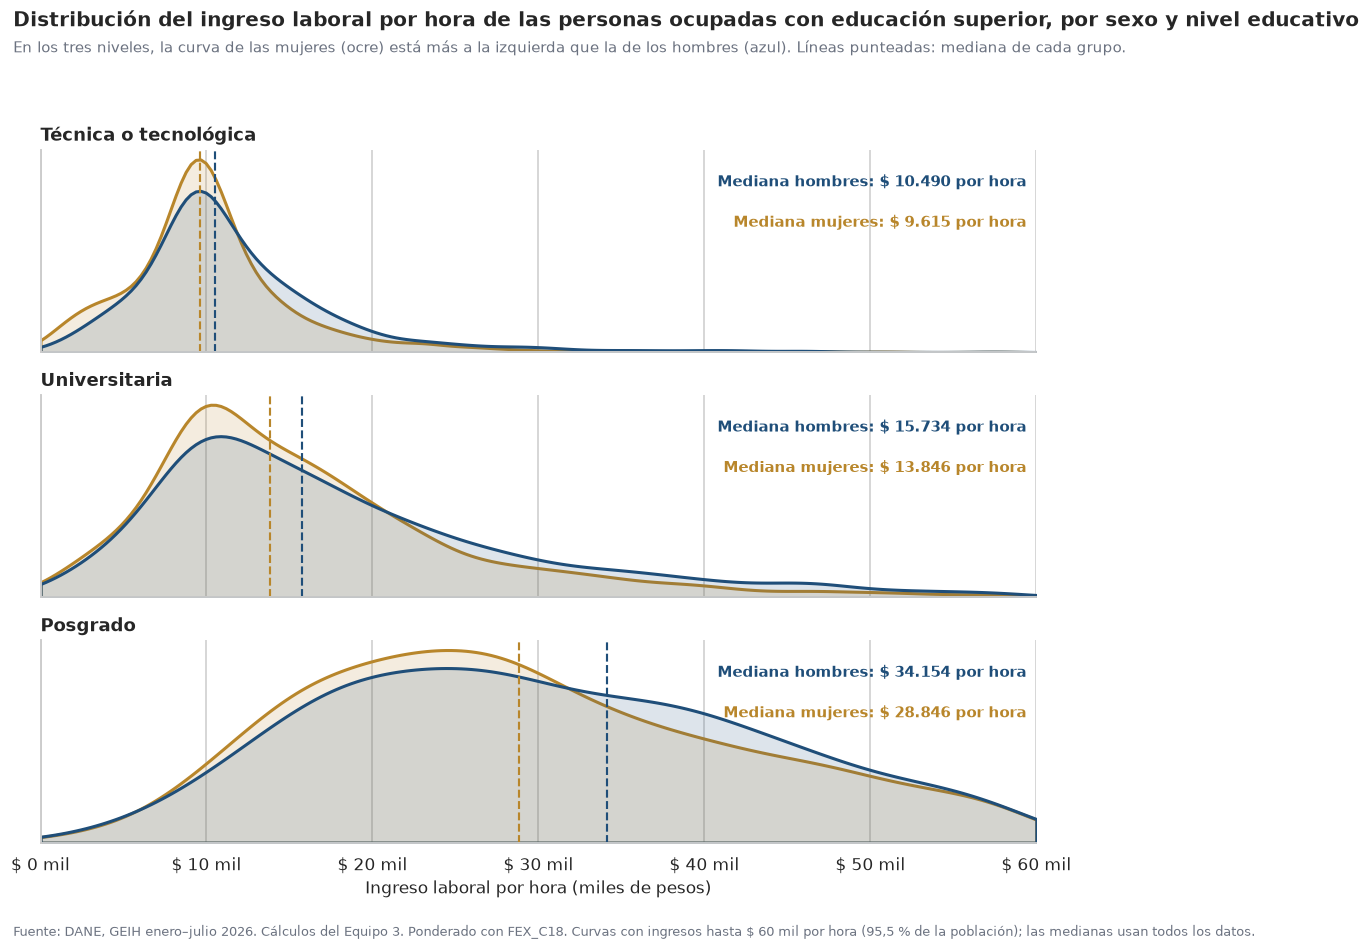

In [13]:
limite_x = 60   # miles de pesos por hora (percentil 95,5 ponderado)
datos["ingreso_hora_miles"] = datos["ingreso_hora"] / 1000
ETIQUETA_PLURAL = {"Hombre": "hombres", "Mujer": "mujeres"}
dentro = datos.loc[datos["ingreso_hora_miles"] <= limite_x, "FEX"].sum() / datos["FEX"].sum() * 100
print(f"Población con ingreso por hora hasta $ {limite_x} mil: {pct(dentro)}")

fig, ejes = plt.subplots(3, 1, figsize=(10, 8.5), sharex=True)
medianas_g1 = {}

for ax, nivel in zip(ejes, ORDEN_NIVEL):
    subconjunto = datos[datos["nivel"] == nivel]
    sns.kdeplot(
        data=subconjunto[subconjunto["ingreso_hora_miles"] <= limite_x], x="ingreso_hora_miles", hue="sexo", hue_order=ORDEN_SEXO,
        weights="FEX", common_norm=False, fill=True, alpha=0.15, linewidth=2,
        palette=COLORES, clip=(0, limite_x), bw_adjust=1.2, legend=False, ax=ax,
    )
    for i, sexo in enumerate(ORDEN_SEXO):
        grupo = subconjunto[subconjunto["sexo"] == sexo]
        mediana = mediana_ponderada(grupo["ingreso_hora_miles"], grupo["FEX"])
        medianas_g1[(nivel, sexo)] = mediana * 1000
        ax.axvline(mediana, color=COLORES[sexo], linestyle="--", linewidth=1.4)
        ax.text(limite_x * 0.99, ax.get_ylim()[1] * (0.82 - 0.2 * i),
                f"Mediana {ETIQUETA_PLURAL[sexo]}: $ {miles(mediana * 1000)} por hora",
                color=COLORES[sexo], fontsize=10, fontweight="bold", ha="right")
    ax.set_title(nivel, loc="left", fontsize=11.5)
    ax.set_ylabel("")
    ax.set_yticks([])
    ax.grid(axis="y", visible=False)

ejes[-1].set_xlim(0, limite_x)
ejes[-1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"$ {v:.0f} mil"))
ejes[-1].set_xlabel("Ingreso laboral por hora (miles de pesos)")

fig.suptitle("Distribución del ingreso laboral por hora de las personas ocupadas con "
             "educación superior, por sexo y nivel educativo",
             x=0.02, ha="left", fontsize=13, fontweight="bold")
fig.text(0.02, 0.935, "En los tres niveles, la curva de las mujeres (ocre) está más a la izquierda "
         "que la de los hombres (azul). Líneas punteadas: mediana de cada grupo.",
         fontsize=10, color=NEUTRO)
fig.text(0.02, -0.01, FUENTE + " Ponderado con FEX_C18. Curvas con ingresos hasta $ 60 mil por hora "
         "(95,5 % de la población); las medianas usan todos los datos.", fontsize=8.5, color=NEUTRO)
fig.tight_layout(rect=(0, 0.01, 1, 0.92))
fig.savefig(CARPETA_IMG / "python_g1_distribucion_ingreso_hora.png")
plt.show()

In [14]:
# Medianas que se citan en la lectura
pd.DataFrame(medianas_g1, index=["Mediana ingreso por hora"]).T.unstack().map(lambda v: "$ " + miles(v))

Mediana ingreso por hora          
                                        Hombre     Mujer
Posgrado                              $ 34.154  $ 28.846
Técnica o tecnológica                 $ 10.490   $ 9.615
Universitaria                         $ 15.734  $ 13.846

**Lectura.** En los tres niveles educativos la distribución de las mujeres está corrida hacia ingresos más bajos. La diferencia no se limita a los extremos: también se ve en la parte central, donde está la mayoría.

- **Técnica o tecnológica:** mediana de $ 9.615 por hora para las mujeres frente a $ 10.490 para los hombres.
- **Universitaria:** $ 13.846 frente a $ 15.734.
- **Posgrado:** $ 28.846 frente a $ 34.154.

En los programas técnicos las dos curvas tienen un pico estrecho y alto: la mitad central de las personas (del percentil 25 al 75) gana entre unos $ 8 mil y $ 13 mil por hora, y en ese tramo las dos curvas casi coinciden. En universitaria y posgrado las curvas son más anchas y la de los hombres tiene más peso en los ingresos altos.

Para la audiencia, el mensaje es que obtener un título más alto se asocia con ingresos más altos para las mujeres (la mediana pasa de unos $ 9.600 a unos $ 28.800 por hora), pero en ningún nivel la curva coincide con la de los hombres. El gráfico describe diferencias y no explica sus causas: no tiene en cuenta la carrera, el cargo ni la experiencia.

### Gráfico 2. Brecha por hora según grupo de edad

**Qué necesita ver la audiencia.** La audiencia está en el grupo de 18 a 28 años. Le sirve saber qué brecha hay al empezar y cómo es en los grupos de más edad, que es el mercado al que va a llegar con los años.

**Por qué barras con intervalo.** Hay una sola cifra por grupo, así que las barras son la forma más directa de comparar. La línea negra de cada barra es el intervalo de confianza del 95 % calculado con el bootstrap. Si es larga, la cifra es menos precisa: le pasa al grupo de 60 años y más, que tiene menos personas en la muestra. La barra del grupo de la audiencia va en color de acento y las demás en gris, para que el ojo la encuentre de inmediato. La línea punteada es la brecha de todas las edades juntas.

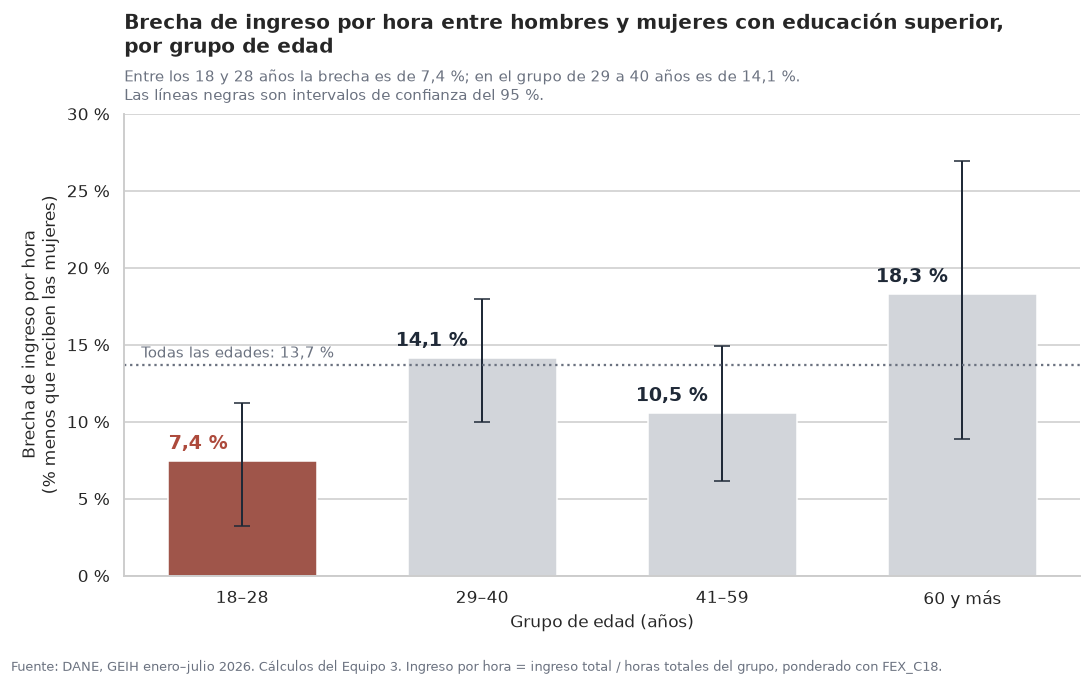

,grupo_edad,personas_muestra,brecha,intervalo
0,18–28,16714,"7,4 %","3,2 % a 11,2 %"
1,29–40,28717,"14,1 %","10,0 % a 17,9 %"
2,41–59,25849,"10,5 %","6,2 % a 14,9 %"
3,60 y más,5122,"18,3 %","8,9 % a 27,0 %"


In [15]:
filas = []
for grupo, tabla in datos.dropna(subset=["grupo_edad"]).groupby("grupo_edad", observed=True):
    resultado = brecha_con_intervalo(tabla)
    filas.append({"grupo_edad": grupo, "personas_muestra": len(tabla), **resultado})
brecha_edad = pd.DataFrame(filas)

colores_barras = [ACENTO if g == "18–28" else GRIS_CLARO for g in brecha_edad["grupo_edad"]]

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=brecha_edad, x="grupo_edad", y="brecha", order=ORDEN_EDAD,
            hue="grupo_edad", palette=dict(zip(brecha_edad["grupo_edad"], colores_barras)),
            legend=False, width=0.62, ax=ax)
ax.errorbar(x=range(len(brecha_edad)), y=brecha_edad["brecha"],
            yerr=[brecha_edad["brecha"] - brecha_edad["ic_inf"],
                  brecha_edad["ic_sup"] - brecha_edad["brecha"]],
            fmt="none", ecolor="#1F2937", elinewidth=1.3, capsize=5)

for i, fila in brecha_edad.iterrows():
    ax.text(i - 0.06, fila["brecha"] + 0.5, pct(fila["brecha"]), ha="right", va="bottom",
            fontsize=12.5, fontweight="bold", color=ACENTO if fila["grupo_edad"] == "18–28" else "#1F2937")

ax.axhline(total_sup["brecha"], color=NEUTRO, linestyle=":", linewidth=1.5)
ax.text(-0.42, total_sup["brecha"] + 0.5, f"Todas las edades: {pct(total_sup['brecha'])}",
        ha="left", fontsize=9.5, color=NEUTRO)

ax.set_ylim(0, 30)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f} %"))
ax.set_xlabel("Grupo de edad (años)")
ax.set_ylabel("Brecha de ingreso por hora\n(% menos que reciben las mujeres)")
jovenes_edad = brecha_edad.set_index("grupo_edad").loc["18–28", "brecha"]
adultos_edad = brecha_edad.set_index("grupo_edad").loc["29–40", "brecha"]
ax.set_title("Brecha de ingreso por hora entre hombres y mujeres con educación superior,\n"
             "por grupo de edad", loc="left", pad=40)
ax.text(0, 1.03, f"Entre los 18 y 28 años la brecha es de {pct(jovenes_edad)}; en el grupo de 29 a 40 "
        f"años es de {pct(adultos_edad)}.\nLas líneas negras son intervalos de confianza del 95 %.",
        transform=ax.transAxes, fontsize=9.8, color=NEUTRO)
fig.text(0.01, -0.03, FUENTE + " Ingreso por hora = ingreso total / horas totales del grupo, "
         "ponderado con FEX_C18.", fontsize=8.5, color=NEUTRO)
fig.tight_layout()
fig.savefig(CARPETA_IMG / "python_g2_brecha_por_edad.png")
plt.show()

brecha_edad.assign(
    brecha=lambda t: t["brecha"].map(pct),
    intervalo=lambda t: t["ic_inf"].map(pct) + " a " + t["ic_sup"].map(pct),
)[["grupo_edad", "personas_muestra", "brecha", "intervalo"]]

In [16]:
# ¿La diferencia entre 18–28 y 29–40 es mayor que el margen de error?
# Los dos grupos son personas distintas, así que el error de la diferencia se aproxima
# combinando los errores de cada grupo (ancho del intervalo / 3,92 = error estándar).
e = brecha_edad.set_index("grupo_edad")
error = lambda g: (e.loc[g, "ic_sup"] - e.loc[g, "ic_inf"]) / 3.92
diferencia = e.loc["29–40", "brecha"] - e.loc["18–28", "brecha"]
error_dif = np.hypot(error("29–40"), error("18–28"))
print(f"Diferencia 29–40 menos 18–28: {diferencia:.1f} puntos porcentuales "
      f"(IC 95 % aprox.: {diferencia - 1.96 * error_dif:.1f} a {diferencia + 1.96 * error_dif:.1f})")

Diferencia 29–40 menos 18–28: 6.7 puntos porcentuales (IC 95 % aprox.: 1.0 a 12.3)


**Lectura.**

- **18 a 28 años: 7,4 %** (intervalo de 3,2 % a 11,2 %). *Qué transmite:* entre jóvenes con educación superior, **por cada $ 100 que recibe por hora un hombre, una mujer recibe $ 92,60**.
- **29 a 40 años: 14,1 %** (intervalo de 10,0 % a 17,9 %). Por cada $ 100 de un hombre, una mujer recibe $ 85,90. Es casi el doble que en el grupo joven.
- **¿Es real esa diferencia entre grupos?** La distancia es de 6,7 **puntos porcentuales** (14,1 − 7,4). Su intervalo aproximado va de 1,0 a 12,3 puntos (celda anterior). Como no incluye el 0, la diferencia entre los dos grupos no se explica solo por el azar de la muestra.
- **41 a 59 años (10,5 %) y 60 y más (18,3 %):** la brecha sigue presente. El intervalo del último grupo es muy ancho (de 8,9 % a 27,0 %) porque tiene pocas personas en la muestra; esa cifra es poco precisa.

**Qué le dice esto a la audiencia.** La diferencia ya existe al comenzar la vida laboral, aunque es menor, y es más alta en las edades en las que muchas personas consolidan su carrera.

**Cuidado con la lectura.** Son personas distintas medidas en el mismo periodo, no las mismas personas a lo largo de su vida. El gráfico no muestra que la brecha "crezca" para una mujer joven de hoy, ni explica por qué es mayor entre los 29 y 40 años. Esa pregunta queda abierta para otros datos, como los de cuidado y maternidad, que esta selección de la GEIH no permite separar.

## 4. Visualización interactiva (Plotly)

### Explorador: ¿qué pasa en el sector donde quiero trabajar?

**Por qué interactivo.** La audiencia quiere ubicar su propio caso: su edad y el sector donde piensa trabajar. Con 18 sectores y 5 grupos de edad, un gráfico estático necesitaría 90 versiones. Aquí el menú cambia el grupo de edad y, al pasar el cursor, cada punto muestra el ingreso por hora, el ingreso mensual promedio, la brecha y cuántas personas hay en la muestra.

**Cómo leerlo.**
- **Panel izquierdo:** cada fila es un sector. El punto **azul** es el ingreso por hora de los hombres y el **ocre** el de las mujeres. Mientras más larga la línea que los une, más grande la diferencia. A la derecha de cada fila, el texto dice cuánto menos (en rojo) o cuánto más (en gris) reciben las mujeres por hora. Los sectores están ordenados de mayor a menor brecha.
- **Panel derecho:** cuántas personas con educación superior trabajan en el sector (promedio mensual), separadas en hombres y mujeres. Muestra qué tan grande es cada sector y si en él trabajan más mujeres o más hombres.
- Los ejes no cambian al cambiar de grupo de edad, para que las comparaciones sean justas.

**Regla de calidad.** Se muestran solo los sectores con al menos 50 hombres y 50 mujeres en la muestra para ese grupo de edad. Con menos, la cifra cambia demasiado de una muestra a otra. Por ejemplo, "Hogares como empleadores" casi no tiene hombres con educación superior y no aparece.

In [17]:
MINIMO_MUESTRA = 50
grupos_menu = ["Todas las edades"] + ORDEN_EDAD

filas = []
for grupo in grupos_menu:
    tabla_grupo = datos if grupo == "Todas las edades" else datos[datos["grupo_edad"] == grupo]
    for sector, tabla in tabla_grupo.groupby("sector"):
        n = tabla["sexo"].value_counts()
        if n.get("Hombre", 0) < MINIMO_MUESTRA or n.get("Mujer", 0) < MINIMO_MUESTRA:
            continue
        h, m = tabla[tabla.sexo == "Hombre"], tabla[tabla.sexo == "Mujer"]
        filas.append({
            "grupo": grupo, "sector": sector,
            "hora_hombres": ingreso_por_hora(h), "hora_mujeres": ingreso_por_hora(m),
            "mes_hombres": ingreso_mensual(h), "mes_mujeres": ingreso_mensual(m),
            "brecha": brecha(tabla),
            "n_hombres": len(h), "n_mujeres": len(m),
            # 7 meses acumulados: se divide por 7 para tener el promedio de ocupados por mes
            "ocupados_hombres": h["FEX"].sum() / 7, "ocupados_mujeres": m["FEX"].sum() / 7,
        })
sectores = pd.DataFrame(filas)
sectores["ocupados_mes"] = sectores["ocupados_hombres"] + sectores["ocupados_mujeres"]
sectores["pct_mujeres"] = sectores["ocupados_mujeres"] / sectores["ocupados_mes"] * 100
sectores.groupby("grupo", sort=False).size().rename("sectores mostrados").to_frame()

,sectores mostrados
grupo,
Todas las edades,18
18–28,17
29–40,18
41–59,17
60 y más,8


In [18]:
from plotly.subplots import make_subplots

# Fuente pensada para pantalla: se usa la primera que tenga instalada el computador que abre el HTML
FUENTE_TABLERO = "Inter, 'Segoe UI', Roboto, 'Helvetica Neue', Arial, sans-serif"
TRAZAS_POR_GRUPO = 6   # línea, hombres, mujeres, etiqueta de brecha, barra hombres, barra mujeres

limite_x = sectores[["hora_hombres", "hora_mujeres"]].max().max() * 1.25   # deja espacio a la etiqueta
limite_barras = sectores["ocupados_mes"].max() * 1.05


def texto_brecha(valor):
    return f"{pct(valor)} menos" if valor > 0 else f"{pct(-valor)} más"


def orden_sectores(grupo):
    # Plotly dibuja la primera categoría abajo: se ordena de menor a mayor para que la mayor brecha quede arriba
    return sectores[sectores["grupo"] == grupo].sort_values("brecha")["sector"].tolist()


fig = make_subplots(rows=1, cols=2, shared_yaxes=True, column_widths=[0.7, 0.3],
                    horizontal_spacing=0.03,
                    subplot_titles=("<b>Ingreso laboral por hora</b>",
                                    "<b>Personas ocupadas en el sector</b>"))

for i, grupo in enumerate(grupos_menu):
    t = sectores[sectores["grupo"] == grupo]
    visible = i == 0

    # Línea que une a hombres y mujeres de cada sector
    xs, ys = [], []
    for _, fila in t.iterrows():
        xs += [fila["hora_mujeres"], fila["hora_hombres"], None]
        ys += [fila["sector"], fila["sector"], None]
    fig.add_trace(go.Scatter(x=xs, y=ys, mode="lines", line=dict(color="#CBD2DA", width=6),
                             hoverinfo="skip", showlegend=False, visible=visible), 1, 1)

    # Puntos de hombres y de mujeres, con todo el detalle en el cursor
    for sexo, col_hora, col_mes, col_n in [("Hombre", "hora_hombres", "mes_hombres", "n_hombres"),
                                           ("Mujer", "hora_mujeres", "mes_mujeres", "n_mujeres")]:
        detalle = np.column_stack([
            t["sector"], t[col_hora].map(miles), t[col_mes].map(miles), t[col_n].map(miles),
            t["brecha"].map(texto_brecha), t["pct_mujeres"].map(lambda v: pct(v, 0)),
        ])
        extra = ("Frente a los hombres del sector: <b>%{customdata[4]}</b> por hora<br>"
                 if sexo == "Mujer" else "")
        fig.add_trace(go.Scatter(
            x=t[col_hora], y=t["sector"], mode="markers", name={"Hombre": "Hombres", "Mujer": "Mujeres"}[sexo],
            legendgroup=sexo, showlegend=visible, visible=visible,
            marker=dict(size=17, color=COLORES[sexo], line=dict(color="white", width=2)),
            customdata=detalle,
            hovertemplate=(
                "<b>%{customdata[0]}</b><br>"
                f"<span style='color:{COLORES[sexo]}'><b>{'Hombres' if sexo == 'Hombre' else 'Mujeres'} "
                "con educación superior</b></span><br><br>"
                "Por hora: <b>$ %{customdata[1]}</b><br>"
                "Al mes (promedio): $ %{customdata[2]}<br>"
                + extra +
                "<br><span style='color:#6B7280'>Mujeres entre los ocupados del sector: %{customdata[5]}<br>"
                "Personas en la muestra: %{customdata[3]}</span><extra></extra>"
            ),
        ), 1, 1)

    # Etiqueta de la brecha al final de cada fila
    fig.add_trace(go.Scatter(
        x=t[["hora_hombres", "hora_mujeres"]].max(axis=1) + limite_x * 0.02, y=t["sector"],
        mode="text", text=t["brecha"].map(texto_brecha), textposition="middle right",
        textfont=dict(size=13, color=np.where(t["brecha"] > 0, ACENTO, NEUTRO).tolist()),
        hoverinfo="skip", showlegend=False, visible=visible), 1, 1)

    # Tamaño del sector: ocupados con educación superior por sexo (barras apiladas)
    for sexo, columna in [("Hombre", "ocupados_hombres"), ("Mujer", "ocupados_mujeres")]:
        fig.add_trace(go.Bar(
            x=t[columna], y=t["sector"], orientation="h", marker_color=COLORES[sexo], opacity=0.85,
            legendgroup=sexo, showlegend=False, visible=visible,
            customdata=np.column_stack([t["sector"], t[columna].map(miles), t["pct_mujeres"].map(lambda v: pct(v, 0))]),
            hovertemplate=("<b>%{customdata[0]}</b><br>"
                           f"{'Hombres' if sexo == 'Hombre' else 'Mujeres'} ocupados con educación superior: "
                           "<b>%{customdata[1]}</b> por mes<br>"
                           "Mujeres en el sector: %{customdata[2]}<extra></extra>"),
        ), 1, 2)


def titulo(grupo):
    return ("<b>Ingreso laboral por hora de mujeres y hombres con educación superior, por sector económico</b>"
            f"<br><span style='font-size:15px;color:{NEUTRO}'>Grupo de edad: <b>{grupo}</b> · "
            "Sectores ordenados de mayor a menor brecha · Colombia, enero–julio 2026</span>")


botones = []
for i, grupo in enumerate(grupos_menu):
    visibles = [False] * (TRAZAS_POR_GRUPO * len(grupos_menu))
    visibles[i * TRAZAS_POR_GRUPO:(i + 1) * TRAZAS_POR_GRUPO] = [True] * TRAZAS_POR_GRUPO
    leyenda = [v and (k % TRAZAS_POR_GRUPO in (1, 2)) for k, v in enumerate(visibles)]
    orden = orden_sectores(grupo)
    botones.append(dict(label=grupo, method="update",
                        args=[{"visible": visibles, "showlegend": leyenda},
                              {"title.text": titulo(grupo),
                               "yaxis.categoryarray": orden, "yaxis2.categoryarray": orden}]))

fig.update_layout(
    template="plotly_white", height=980, barmode="stack",
    font=dict(family=FUENTE_TABLERO, size=14, color="#1F2937"),
    title=dict(text=titulo(grupos_menu[0]), x=0.01, xanchor="left", y=0.975, font=dict(size=21)),
    separators=",.",
    legend=dict(orientation="h", x=0, xanchor="left", y=1.045, yanchor="bottom",
                font=dict(size=14), itemsizing="constant", title_text=""),
    updatemenus=[dict(buttons=botones, direction="down", x=1, xanchor="right", y=1.06,
                      yanchor="bottom", showactive=True, bgcolor="white", bordercolor="#CBD2DA",
                      font=dict(size=14), pad=dict(r=6, t=4, b=4, l=6))],
    margin=dict(t=175, b=120, l=40, r=40),
    hoverlabel=dict(bgcolor="white", bordercolor="#CBD2DA", font=dict(family=FUENTE_TABLERO, size=14)),
    bargap=0.45,
)
fig.update_yaxes(type="category", categoryorder="array", categoryarray=orden_sectores(grupos_menu[0]),
                 tickfont=dict(size=14), ticksuffix="   ", showgrid=False)
fig.update_xaxes(row=1, col=1, range=[0, limite_x], tickprefix="$ ", tickformat=",.0f",
                 title=dict(text="Pesos por hora trabajada", standoff=14), gridcolor="#EEF0F3", zeroline=False)
fig.update_xaxes(row=1, col=2, range=[0, limite_barras], tickformat=",.0f",
                 title=dict(text="Ocupados por mes", standoff=14), gridcolor="#EEF0F3", zeroline=False)
fig.update_annotations(font=dict(size=16), yshift=8)   # títulos de los dos paneles

fig.add_annotation(text="Grupo de edad", x=0.86, xref="paper", xanchor="right", y=1.075, yref="paper",
                   yanchor="bottom", showarrow=False, font=dict(size=14, color=NEUTRO))
fig.add_annotation(
    text=("Texto rojo: cuánto menos reciben las mujeres por hora · Texto gris: reciben igual o más. "
          "Solo sectores con al menos 50 hombres y 50 mujeres en la muestra.<br>" + FUENTE +
          " Ingreso por hora = ingreso total / horas totales del grupo, ponderado con FEX_C18."),
    x=0, xref="paper", y=-0.1, yref="paper", xanchor="left", yanchor="top", showarrow=False,
    align="left", font=dict(size=12, color=NEUTRO))

fig.write_html(CARPETA_HTML / "Equipo3_Proyecto3_Plotly_Sectores.html", include_plotlyjs=True,
               config={"displaylogo": False, "responsive": True})
fig.show()

In [19]:
# Cifras citadas en la lectura: sectores con educación superior, todas las edades
(sectores[sectores["grupo"] == "Todas las edades"]
 .sort_values("brecha", ascending=False)
 .assign(hombres=lambda t: t["hora_hombres"].map(miles), mujeres=lambda t: t["hora_mujeres"].map(miles),
         brecha=lambda t: t["brecha"].map(pct), ocupados_mes=lambda t: t["ocupados_mes"].map(miles),
         pct_mujeres=lambda t: t["pct_mujeres"].map(lambda v: pct(v, 0)))
 [["sector", "hombres", "mujeres", "brecha", "ocupados_mes", "pct_mujeres", "n_hombres", "n_mujeres"]]
 .reset_index(drop=True))

,sector,hombres,mujeres,brecha,ocupados_mes,pct_mujeres,n_hombres,n_mujeres
0,Salud y asistencia social,30.568,17.642,"42,3 %",905.129,76 %,2289,6794
1,Actividades inmobiliarias,25.986,18.730,"27,9 %",106.884,52 %,413,426
2,Comercio y reparación de vehículos,17.149,12.903,"24,8 %",1.233.096,54 %,5087,6588
3,Información y comunicaciones,33.182,27.069,"18,4 %",340.601,34 %,1533,780
4,Finanzas y seguros,28.294,23.409,"17,3 %",373.835,59 %,1023,1645
5,Alojamiento y servicios de comida,11.855,10.126,"14,6 %",380.187,62 %,1505,2489
6,Industria manufacturera,18.228,15.585,"14,5 %",804.498,43 %,3022,2686
7,Educación,27.719,24.050,"13,2 %",828.983,60 %,3498,5693
8,Otros servicios,14.195,12.448,"12,3 %",326.379,63 %,1191,2128
9,Construcción,18.146,16.820,"7,3 %",314.816,27 %,2071,820


In [20]:
# Grupo de la audiencia: ¿en cuántos sectores las mujeres de 18 a 28 reciben menos por hora?
jovenes = sectores[sectores["grupo"] == "18–28"].sort_values("brecha", ascending=False)
print(f"Sectores con datos suficientes (18–28): {len(jovenes)}")
print(f"Sectores donde las mujeres reciben menos por hora: {(jovenes['brecha'] > 0).sum()}")
jovenes[["sector", "brecha", "n_hombres", "n_mujeres"]].assign(
    brecha=lambda t: t["brecha"].map(pct)).reset_index(drop=True)

Sectores con datos suficientes (18–28): 17
Sectores donde las mujeres reciben menos por hora: 12


,sector,brecha,n_hombres,n_mujeres
0,Comercio y reparación de vehículos,"20,0 %",1331,1727
1,Servicios administrativos y de apoyo,"18,5 %",357,430
2,Educación,"16,6 %",387,673
3,Alojamiento y servicios de comida,"14,4 %",643,954
4,Información y comunicaciones,"14,4 %",429,208
5,Actividades inmobiliarias,"13,3 %",50,55
6,Salud y asistencia social,"11,7 %",497,1523
7,Finanzas y seguros,"11,4 %",190,288
8,Otros servicios,"9,2 %",249,597
9,Industria manufacturera,"5,3 %",709,661


**Cómo usarlo.** Elige un grupo de edad en el menú de la esquina superior derecha y pasa el cursor por los puntos o las barras. Al cambiar a "18–28" todos los puntos se mueven a la izquierda, porque al inicio de la vida laboral los ingresos por hora son menores para ambos sexos. Lo que interesa es **la distancia entre el punto azul y el ocre** de cada fila y el texto de la derecha. En la leyenda se puede hacer clic en "Hombres" o "Mujeres" para ocultar ese grupo.

**Lectura.** Con todas las edades, en 14 de los 18 sectores el punto ocre (mujeres) está a la izquierda del azul (hombres): las mujeres con educación superior reciben menos por hora en casi todas las actividades. Las brechas más grandes están en **salud y asistencia social** (42,3 %), **actividades inmobiliarias** (27,9 %) y **comercio** (24,8 %). En salud, por cada $ 100 que recibe por hora un hombre, una mujer recibe $ 57,70. Además, es uno de los sectores que más mujeres con educación superior emplea (ellas son el 76 % de los ocupados con educación superior del sector, panel derecho). En ese sector la cifra puede reflejar que hombres y mujeres ocupan cargos distintos, por ejemplo medicina frente a enfermería; el dato no separa esas profesiones.

En unos pocos sectores las mujeres reciben igual o más por hora: minería, arte y entretenimiento, transporte y administración pública. En minería y arte la muestra de mujeres es pequeña (115 y 432 personas). En administración pública los salarios siguen escalas fijas, lo cual es consistente con una brecha cercana a cero, aunque el dato no permite afirmarlo.

En el grupo de 18 a 28 años, las mujeres reciben menos por hora en 12 de los 17 sectores con datos suficientes. El orden cambia: las brechas más altas están en comercio (20,0 %), servicios administrativos y de apoyo (18,5 %) y educación (16,6 %), mientras que en salud la brecha baja a 11,7 %. En los otros cinco (transporte, agro y pesca, administración pública, construcción y electricidad, gas y agua) las jóvenes reciben igual o más por hora que los jóvenes, aunque en algunos la muestra de mujeres es pequeña (71 en electricidad, gas y agua y 107 en agro y pesca). Para la audiencia, la pregunta "¿cuánto paga este sector a hombres y mujeres con mi nivel?" tiene respuestas muy distintas según la actividad. Vale la pena hacerla al buscar empleo.

## 5. Tabla para el mapa en R

El mapa departamental se hace en R (`r/Equipo3_Proyecto3_Mapa.Rmd`). Aquí calculamos, para cada departamento, la brecha de ingreso por hora en educación superior (todas las edades) con su intervalo de confianza y su coeficiente de variación (CV).

**¿Por qué todas las edades y no solo 18–28?** Porque con solo jóvenes, varios departamentos quedan con menos de 30 hombres en la muestra. La GEIH no da para tanto detalle y el mapa no sería confiable.

**¿Qué departamentos se marcan?** La representatividad de la GEIH por departamento es anual, y aquí hay 7 meses. Por eso se exportan dos indicadores de precisión:

- **CV del ingreso por hora** de hombres y de mujeres, que se compara con los umbrales del DANE: hasta 7 % precisa, de 7 % a 15 % aceptable, de 15 % a 20 % regular y más de 20 % poco precisa.
- **Brecha concluyente**: el intervalo de confianza del 95 % no incluye el 0. Si lo incluye, con estos datos no se puede afirmar que exista diferencia en ese departamento, y el mapa lo muestra en gris.

In [21]:
filas = []
for dpto, tabla in datos.groupby("DPTO"):
    resultado = brecha_con_intervalo(tabla)
    filas.append({
        "DPTO": dpto,
        "n_hombres": (tabla.sexo == "Hombre").sum(), "n_mujeres": (tabla.sexo == "Mujer").sum(),
        "hora_hombres": round(ingreso_por_hora(tabla[tabla.sexo == "Hombre"])),
        "hora_mujeres": round(ingreso_por_hora(tabla[tabla.sexo == "Mujer"])),
        "brecha_mensual": round(brecha(tabla, ingreso_mensual), 2),
        "brecha_hora": round(resultado["brecha"], 2),
        "ic_inf": round(resultado["ic_inf"], 2), "ic_sup": round(resultado["ic_sup"], 2),
        "cv_hombres": round(resultado["cv_hombres"], 2), "cv_mujeres": round(resultado["cv_mujeres"], 2),
    })

brecha_dpto = pd.DataFrame(filas)
brecha_dpto["concluyente"] = (brecha_dpto["ic_inf"] > 0) | (brecha_dpto["ic_sup"] < 0)
brecha_dpto["cv_max"] = brecha_dpto[["cv_hombres", "cv_mujeres"]].max(axis=1)
brecha_dpto["precision_dane"] = pd.cut(brecha_dpto["cv_max"], [0, 7, 15, 20, np.inf],
                                       labels=["Precisa", "Aceptable", "Regular", "Poco precisa"])

brecha_dpto.to_csv(CARPETA_PROCESADOS / "brecha_departamento.csv", index=False, encoding="utf-8")

print(f"Departamentos: {len(brecha_dpto)}")
print(f"Con brecha concluyente (IC 95 % sin el 0): {brecha_dpto['concluyente'].sum()}")
print("Precisión según CV del ingreso por hora:")
print(brecha_dpto["precision_dane"].value_counts().to_string())
brecha_dpto.sort_values("brecha_hora", ascending=False).head(8)

Departamentos: 33
Con brecha concluyente (IC 95 % sin el 0): 21
Precisión según CV del ingreso por hora:
precision_dane
Precisa         28
Aceptable        5
Regular          0
Poco precisa     0


,DPTO,n_hombres,n_mujeres,hora_hombres,hora_mujeres,brecha_mensual,brecha_hora,ic_inf,ic_sup,cv_hombres,cv_mujeres,concluyente,cv_max,precision_dane
30,95,217,319,18781,13502,32.40,28.11,15.50,38.71,8.25,5.55,True,8.25,Aceptable
25,85,293,410,21463,15600,33.35,27.31,15.61,38.46,7.77,4.18,True,7.77,Aceptable
5,17,2102,2492,22116,16604,28.47,24.92,19.22,29.91,3.30,2.19,True,3.30,Precisa
18,63,1434,1623,21765,16528,28.82,24.06,16.98,32.07,4.87,2.34,True,4.87,Precisa
15,50,1227,1441,20049,15874,26.55,20.82,14.99,26.53,2.94,2.64,True,2.94,Precisa
6,18,842,1020,18403,14703,23.78,20.11,10.08,29.02,5.55,3.23,True,5.55,Precisa
32,99,127,166,18363,14679,24.69,20.06,1.28,35.56,10.29,4.97,True,10.29,Aceptable
23,76,1878,2085,20119,16100,24.51,19.98,14.17,25.19,3.40,2.31,True,3.40,Precisa


**Lectura.** De los 33 departamentos (incluida Bogotá), 21 tienen una brecha concluyente y 12 no. En estos últimos el intervalo incluye el 0, sobre todo en departamentos con pocas personas en la muestra o con brechas pequeñas. El CV del ingreso por hora no supera el 15 % en ningún departamento, así que las estimaciones de ingreso son precisas o aceptables. Lo incierto es la *diferencia* entre hombres y mujeres, y por eso el mapa usa el criterio del intervalo. Los nombres de los departamentos los pone R desde la cartografía del DANE, con el código `DPTO`.

## 6. Hallazgos para la narrativa

| # | Hallazgo (lo que se observa) | Cifra | Dónde se ve |
|---|---|---|---|
| 1 | Con educación superior, las mujeres reciben menos por hora que los hombres con el mismo nivel | 13,7 % (IC 11,2 % – 16,3 %) | Cifras de control |
| 2 | La diferencia aparece en toda la distribución, no solo en los ingresos altos, y en los tres niveles | Medianas: técnica $ 9.615 vs. $ 10.490 · universitaria $ 13.846 vs. $ 15.734 · posgrado $ 28.846 vs. $ 34.154 | Gráfico 1 |
| 3 | Al comenzar la vida laboral la brecha es menor; entre los 29 y 40 años es casi el doble | 18–28: 7,4 % · 29–40: 14,1 % | Gráfico 2 |
| 4 | La brecha cambia mucho según el sector | De 42,3 % en salud a valores cercanos a 0 o negativos en administración pública | Plotly |
| 5 | La brecha cambia según el departamento, pero en 12 de 33 los datos no permiten afirmarla | 21 departamentos con brecha concluyente | Mapa en R |

### Limitaciones

1. **No es causalidad.** Son comparaciones descriptivas. No se tienen en cuenta la carrera, el cargo, la experiencia, el tamaño de la empresa ni la formalidad, así que la brecha **no** mide discriminación ni dice por qué existe.
2. **Datos transversales.** Las diferencias entre grupos de edad comparan a personas distintas en el mismo periodo, no la trayectoria de una misma persona.
3. **Solo personas con trabajo remunerado.** La brecha compara a quienes trabajan y reportan ingreso. Quedan fuera, por ejemplo, una persona graduada de una tecnología que está buscando empleo, una profesional que se dedica al cuidado del hogar o una contadora que ayuda sin sueldo en el negocio familiar (5.435 ocupados sin ingreso reportado, 1.535 de ellos con educación superior). Por eso los datos no dicen si a las mujeres les cuesta más conseguir trabajo; esa sería otra brecha.
4. **Ingreso declarado.** `INGLABO` es lo que reporta la persona encuestada; puede haber errores u omisiones. No se eliminaron valores extremos, para que las cifras coincidan con Power BI.
5. **Siete meses.** Las cifras son de enero a julio de 2026, no anuales. La representatividad departamental de la GEIH es anual, por eso el mapa marca los departamentos sin brecha concluyente.
6. **Intervalos aproximados.** El bootstrap por vivienda no reproduce el diseño muestral completo del DANE; los intervalos reales pueden ser algo más amplios.

### Archivos que produce este notebook

| Archivo | Uso |
|---|---|
| `presentacion/img/python_g1_distribucion_ingreso_hora.png` | Diapositiva del gráfico 1 |
| `presentacion/img/python_g2_brecha_por_edad.png` | Diapositiva del gráfico 2 |
| `python/html/Equipo3_Proyecto3_Plotly_Sectores.html` | Explorador interactivo (se abre en cualquier navegador, sin internet) |
| `datos/procesados/brecha_departamento.csv` | Insumo del mapa en R |